# Operations, Monitoring & Evidence
Covers **Stage 4.** Complete every `# TODO` in this notebook **and** in the `src/` modules it imports. 
- Each stage opens with a **sub-task checklist**
- Capture any repo-generated evidence (MLflow UI, Docker build, CI run, drift report) as screenshots/summaries **inside the notebook/report**.

**File ownership** — 
- *Provided:* `config.py`, `src/evaluate.py`. 
- *Provided to extend:* `src/monitoring.py`, `src/retrain.py`, `src/model.py` (EmbeddingExtractor). 
- *You build:* this notebook.

### 0. Setup

In [1]:
import config, json
# TODO: load artifacts/drift_summary.json after running src.monitoring
!python -m src.monitoring

drift_summary = json.load(open(config.ARTIFACT_DIR / "drift_summary.json"))
drift_summary

{'psi_scores': {'brightness': 0.0,
  'contrast': 0.0,
  'edge_density': 1.4169115481195356,
  'sharpness': 0.02343341757485331,
  'mean_intensity': 0.0},
 'embedding_psi': 0.10449454983315759,
 'confidence_ref': 0.9152747838940453,
 'confidence_cur': 0.9968338961577295,
 'confidence_drop': -0.08155911226368429,
 'retrain_recommended': True}

## **Stage 4.1 — Prediction Logging & Confidence Monitoring** <font color="red">[5 marks]</font>

- **4.1.1 — Prediction logging with timestamp [2]** — *to be done in this notebook and the report*
- **4.1.2 — Confidence monitoring reference vs current + threshold [3]** — *to be done in this notebook and the report*

**Objective:** Log predictions and watch mean confidence drift.

**Implement in:** app.py (logging) + src/monitoring.py (confidence)

**Inputs → Outputs:** served predictions → predictions.log; reference vs current → confidence drop + alert

**TODO:** log each prediction with a timestamp (4.1.1); compute mean predicted-confidence on reference vs a current batch with an alert threshold (4.1.2).

**Depends on:** Stage 3.4 completed in Model_Development_and_Tracking.ipynb ·  **Document here:** the confidence reference→current + log tail.

In [2]:
# TODO 4.1.1-4.1.2: show predictions.log tail + confidence block from drift_summary.json

# !tail -n 5 artifacts/predictions.log
# The `tail` command is a native Linux/macOS command, but Windows command prompt (cmd.exe) doesn't know what it is.
# I feel this is the best approach because it works perfectly on any operating system without needing external system tools.

with open(config.ARTIFACT_DIR / "predictions.log") as f:
    lines = f.readlines()
    for line in lines[-5:]:
        print(line, end="")

print("Mean reference confidence:", drift_summary["confidence_ref"])
print("Mean current confidence:", drift_summary["confidence_cur"])
print("Mean confidence drop:", drift_summary["confidence_drop"])

{"time": 1783610887.6745856, "file": "sample.jpg", "label": "ok_front", "is_defective": false, "prob_defect": 0.46167895197868347, "confidence": 0.5383210182189941}
{"time": 1783613469.5245864, "file": "sample.jpg", "label": "ok_front", "is_defective": false, "prob_defect": 0.46167895197868347, "confidence": 0.5383210182189941}
{"time": 1783680969.5311494, "file": "sample.jpg", "label": "def_front", "is_defective": true, "prob_defect": 0.9364546537399292, "confidence": 0.9364546537399292}
{"time": 1783692273.84014, "file": "sample.jpg", "label": "def_front", "is_defective": true, "prob_defect": 0.9364546537399292, "confidence": 0.9364546537399292}
Mean reference confidence: 0.9152747838940453
Mean current confidence: 0.9968338961577295
Mean confidence drop: -0.08155911226368429


## **Stage 4.2 — Statistical Drift Detection (Evidently + PSI)** <font color="red">[8 marks]</font>

- **4.2.1 — Per-image features + Evidently DataDriftPreset [4]** — *to be done in this notebook and the report*
- **4.2.2 — PSI per feature + interpretation [4]**— *to be done in this notebook and the report*

**Objective:** Detect drift in interpretable image features.

**Implement in:** src/monitoring.py

**Inputs → Outputs:** reference vs simulated current batch → per-feature drift + PSI + HTML report

**TODO:** compute image features + run Evidently DataDriftPreset reference vs a simulated current batch (4.2.1); compute PSI per feature + interpret + save drift_report.html (4.2.2).

**Document here:** the per-feature PSI table/plot + dataset_drift flag.

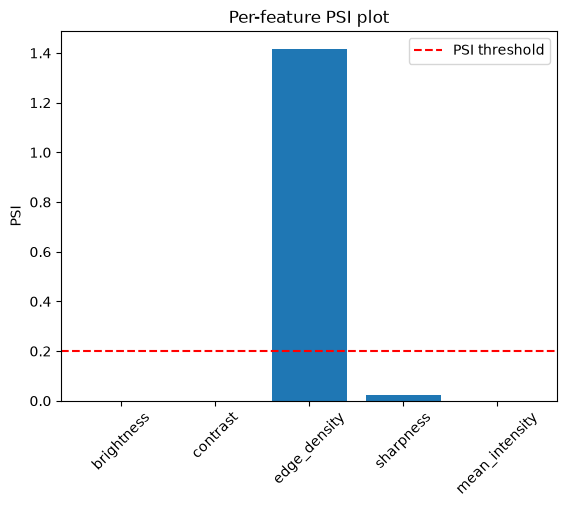

Dataset drift flagged: True


In [3]:
# TODO 4.2.1-4.2.2: !python -m src.monitoring ; bar-plot feature PSI vs the 0.2 threshold

# !python -m src.monitoring (Already ran in the 0.setup cell)

import matplotlib.pyplot as plt
psi_scores = drift_summary["psi_scores"]
plt.bar(psi_scores.keys(), psi_scores.values())
plt.axhline(0.2, color="red", linestyle="--", label="PSI threshold")
plt.xticks(rotation=45)
plt.ylabel("PSI")
plt.title("Per-feature PSI plot")
plt.legend()
plt.show()

print("Dataset drift flagged:", any(v > 0.2 for v in psi_scores.values()))

## **Stage 4.3 — Embedding Drift Detection** <font color="red">[7 marks]</font>

- **4.3.1 — 512-dim embedding extraction (reference + current) [3]** — *to be done in this notebook*
- **4.3.2 — Feature-space drift quantified (PSI) + explanation [4]** — *to be done in this notebook and the report*

### How embedding drift works (conceptual scaffolding — implement these 4 steps)
Raw-pixel features can miss *semantic* drift, so also measure drift in the model's **feature space**:
1. **Feature extraction** — use the model's **penultimate layer** (the 512-dim vector before the final classifier) as an image **embedding** (`EmbeddingExtractor` in `src/model.py`). *(4.3.1)*
2. **Embedding generation** — run the reference set and the current batch through the backbone and collect the embedding vectors (save reference to `reference_embeddings.npz`). *(4.3.1)*
3. **Feature-space comparison** — reduce each embedding to a scalar **distance to the reference centroid** (mean reference embedding) → one distribution per batch. *(4.3.2)*
4. **Drift calculation** — compute **PSI** between the reference and current distance distributions; PSI above ~0.10 signals embedding drift even when raw pixels look similar. *(4.3.2)*

**TODO:** implement steps 1–4 in `src/model.EmbeddingExtractor` + `src/monitoring.py`; report the embedding PSI and whether it exceeds the threshold.

**Document here:** the embedding PSI + a one-line interpretation of why embedding drift differs from feature drift.

In [4]:
# TODO 4.3.1-4.3.2: extract embeddings (reference + current); PSI on distance-to-centroid; print PSI vs 0.10
print("Embedding PSI:", drift_summary["embedding_psi"])
print("Threshold:", config.DRIFT_SHARE_THRESHOLD)
print("Embedding drift flagged:", drift_summary["embedding_psi"] > config.DRIFT_SHARE_THRESHOLD)

print("""
Why embedding drift differs from feature drift?:
Embedding drift captures changes in the model's internal feature space that raw pixel statistics may miss.
Even if brightness or blur look similar, the semantic representation can shift.
Here, the embedding PSI shows whether the backbone's learned features have drifted beyond the 0.10 threshold, which is a more sensitive signal of production drift than feature-level PSI.
""")

Embedding PSI: 0.10449454983315759
Threshold: 0.4
Embedding drift flagged: False

Why embedding drift differs from feature drift?:
Embedding drift captures changes in the model's internal feature space that raw pixel statistics may miss.
Even if brightness or blur look similar, the semantic representation can shift.
Here, the embedding PSI shows whether the backbone's learned features have drifted beyond the 0.10 threshold, which is a more sensitive signal of production drift than feature-level PSI.



## **Stage 4.4 — Retraining Workflow & Triggers** <font color="red">[6 marks]</font>

- **4.4.1 — Measurable retraining triggers [2]** — *to be done in this notebook and the report*
- **4.4.2 — Drift-triggered retraining + new version registered [4]** — *to be done in this notebook and the report*

**Objective:** Retrain a candidate when drift fires.

**Implement in:** src/retrain.py

**Inputs → Outputs:** drift signals → drift-augmented candidate model + new registry version

**TODO:** define multi-signal triggers (drift share / embedding PSI / confidence drop) (4.4.1); on a trigger, train a drift-augmented candidate + register a new version (4.4.2).

**Document here:** the trigger decision + candidate training summary.

In [5]:
# TODO 4.4.1-4.4.2: !python -m src.retrain ; load artifacts/retraining_decision.json
!python -m src.retrain

decision = json.load(open(config.ARTIFACT_DIR / "retraining_decision.json"))
decision


D:\py_test\data_files\Capstone\upGrad-MLOps-Capstone\src\retrain.py:103: FutureWarning: ``mlflow.tracking.client.MlflowClient.get_latest_versions`` is deprecated since 2.9.0. Model registry stages will be removed in a future major release. To learn more about the deprecation of model registry stages, see our migration guide here: https://mlflow.org/docs/latest/model-registry.html#migrating-from-stages
  latest = client.get_latest_versions(config.REGISTERED_MODEL, ["None"])[-1]


{'action': 'rollback',
 'prod_f1': 0.7756849315068494,
 'cand_f1': 0.7742489270386266,
 'prod_metrics': {'accuracy': 0.6335664335664336,
  'precision_defect': 0.6335664335664336,
  'recall_defect': 1.0,
  'f1_defect': 0.7756849315068494,
  'macro_f1': 0.3878424657534247,
  'roc_auc': 0.5,
  'confusion_matrix': [[0, 262], [0, 453]]},
 'production_version': 2,
 'cand_metrics': {'accuracy': 0.6321678321678321,
  'precision_defect': 0.6334269662921348,
  'recall_defect': 0.9955849889624724,
  'f1_defect': 0.7742489270386266,
  'macro_f1': 0.39089804842497367,
  'roc_auc': 0.49970089142780105,
  'confusion_matrix': [[1, 261], [2, 451]]},
 'drift_summary': {'psi_scores': {'brightness': 0.0,
   'contrast': 0.0,
   'edge_density': 1.4169115481195356,
   'sharpness': 0.02343341757485331,
   'mean_intensity': 0.0},
  'embedding_psi': 0.10449454983315759,
  'confidence_ref': 0.9152747838940453,
  'confidence_cur': 0.9968338961577295,
  'confidence_drop': -0.08155911226368429,
  'retrain_recommend

## **Stage 4.5 — Version Comparison & Rollback Governance** <font color="red">[4 marks]</font>

- **4.5.1 — Candidate vs production comparison on drifted batch [2]** — *to be done in this notebook and the report*
- **4.5.2 — Promote-on-improvement-else-rollback gate + decision recorded [2]** — *to be done in this notebook and the report*

**Objective:** Promote only on improvement; otherwise roll back.

**Implement in:** src/retrain.py

**Inputs → Outputs:** candidate vs production on a drifted batch → promote (alias move) OR rollback

**TODO:** compare candidate vs production F1 on the drifted batch (4.5.1); promote to @production only if candidate ≥ prod + epsilon else keep the incumbent + record the decision/version history (4.5.2).

**Document here:** the comparison numbers + the promote/rollback decision.

In [6]:
# TODO 4.5.1-4.5.2: from retraining_decision.json show prod vs candidate F1 + action + production version
print("Production F1:", decision.get("prod_f1"))
print("Candidate F1:", decision.get("cand_f1"))
print("Action:", decision.get("action"))
print("Production version:", decision.get("production_version"))

Production F1: 0.7756849315068494
Candidate F1: 0.7742489270386266
Action: rollback
Production version: 2
